In [10]:
import ants
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
moving_path = "/scratch/anirudhkaushik/Resized_ADNI/ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948398_S38468_I75150_padded_transposed_padded_transposed.nii.gz"
target_path = "/scratch/anirudhkaushik/Resized_ADNI/ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948397_S46683_I105437_padded_transposed_padded_transposed.nii.gz"

moving = ants.image_read(moving_path)
target = ants.image_read(target_path)

# Apply N4 bias field correction
moving = ants.n4_bias_field_correction(moving)
target = ants.n4_bias_field_correction(target)

# Register the images
mytx = ants.registration(fixed=target, moving=moving, type_of_transform='Rigid')
warped_image = ants.apply_transforms(fixed=target, moving=moving, transformlist=mytx['fwdtransforms'])


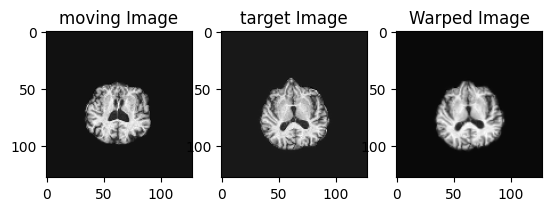

In [11]:

# display the images
plt.figure(1)   # create a new figure
plt.subplot(1, 3, 1)  # this is the first image
plt.imshow(moving.numpy()[:,:, 64], cmap='gray')
plt.title('moving Image')

plt.subplot(1, 3, 2)  # this is the second image
plt.imshow(target.numpy()[:,:, 64], cmap='gray')
plt.title('target Image')

plt.subplot(1, 3, 3)  # this is the third image
plt.imshow(warped_image.numpy()[:,:, 64], cmap='gray')
plt.title('Warped Image')

plt.show()
